In [1]:
print("hello world")


hello world


1. Loading Dataset and Tokenizer...

2. Analyzing Input Column Artifacts...
Total Rows: 20022
Usable Inputs: 10256 (51.22%)
Useless/Artifact Inputs: 9766 (48.78%)

Hunting for Hidden Artifacts (Top 15 Exact Matches in Input Column):
input
                           9764
[1, 2, 3, 4, 5]              57
string = "hello world"       36
hello world                  35
arr = [1, 2, 3, 4, 5]        34
n = 10                       32
n = 5                        31
string = "hello world!"      29
[1, 2, 3, 4]                 27
num = 5                      17
[1, 2, 3]                    15
[1,2,3,4,5]                  15
"hello world!"               14
[1,2,3,4]                    14
list = [1, 2, 3, 4, 5]       14
Name: count, dtype: int64

3. Calculating Token Length Distributions...

Token Length Percentiles (Filtered Data):
       prompt_tokens  completion_tokens  total_tokens
count   20022.000000       20022.000000  20022.000000
mean       76.238488          59.058536    135.297023
std 

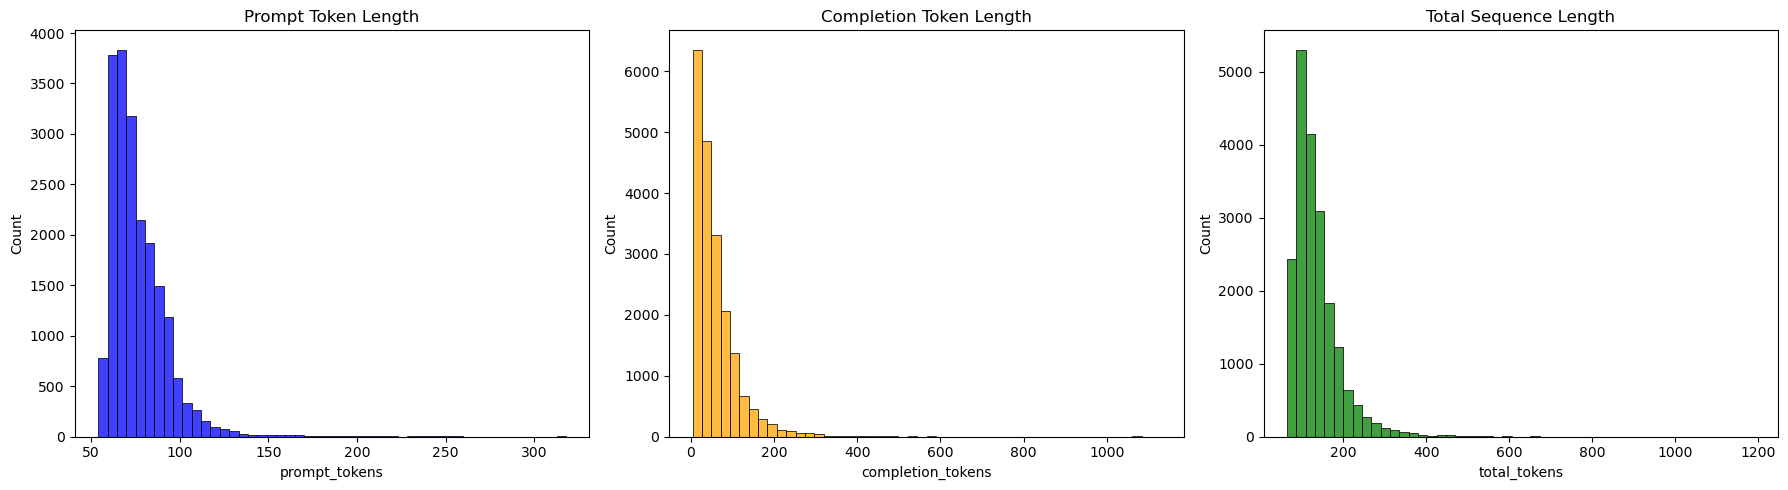


5. Vocabulary Frequency Analysis (Router Prep)...


C:\Users\ozgur\AppData\Local\Temp\ipykernel_16156\2300244154.py:167: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette="viridis")


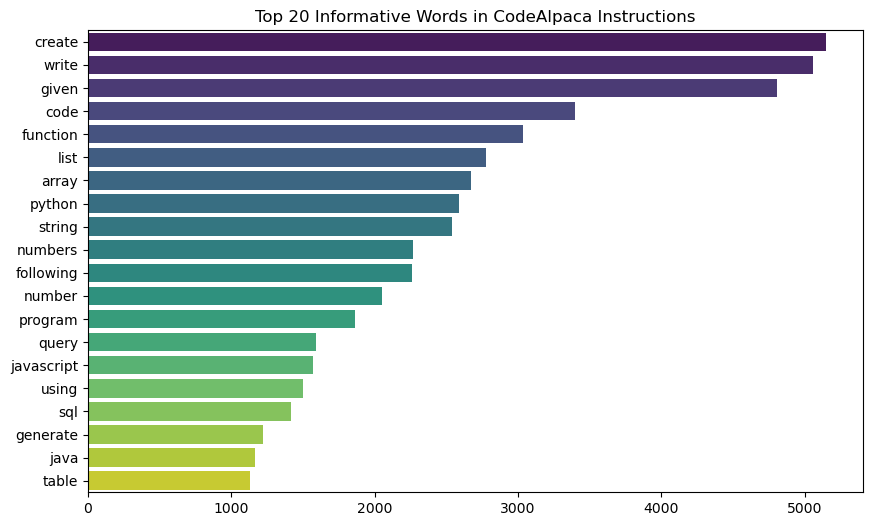

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import CountVectorizer


def run_gsm8k_eda(model_id: str = "meta-llama/Meta-Llama-3.1-8B-Instruct"):
    print("1. Loading Dataset and Tokenizer...")
    dataset = load_dataset("openai/gsm8k", "main")
    train_df = dataset["train"].to_pandas()

    # Load the Llama 3 tokenizer to get accurate subword counts
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    print("\n2. Analyzing Structural Integrity...")
    # Verify the #### delimiter exists in every answer
    missing_delimiter = train_df[~train_df["answer"].str.contains("####")]
    print(f"Rows missing '####' delimiter: {len(missing_delimiter)}")

    # Count frequency of <<equation=answer>> annotations
    train_df["calc_annotations_count"] = train_df["answer"].str.count(r"<<.*?>>")
    print(
        f"Average calculator annotations per answer: {train_df['calc_annotations_count'].mean():.2f}"
    )

    print("\n3. Calculating Token Length Distributions...")

    # Apply Llama 3 Chat Template to calculate true sequence lengths
    def calculate_lengths(row):
        messages = [
            {
                "role": "system",
                "content": "You are a mathematical reasoning assistant. Solve the problem step-by-step and provide the final answer after ####.",
            },
            {"role": "user", "content": row["question"]},
            {"role": "assistant", "content": row["answer"]},
        ]
        # Format string without tokenizing to see raw text
        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)

        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)

        # Tokenize to get lengths
        total_tokens = len(tokenizer.encode(formatted_string))
        prompt_tokens = len(tokenizer.encode(formatted_prompt))
        completion_tokens = total_tokens - prompt_tokens

        return pd.Series([prompt_tokens, completion_tokens, total_tokens])

    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = train_df.apply(
        calculate_lengths, axis=1
    )

    # Output percentiles to dictate max_length parameter
    print("\nToken Length Percentiles:")
    print(
        train_df[["prompt_tokens", "completion_tokens", "total_tokens"]].describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
    )

    print("\n4. Plotting Distributions...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        train_df["prompt_tokens"], bins=50, ax=axes[0], color="blue"
    ).set_title("Prompt Token Length")
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[1], color="orange"
    ).set_title("Completion Token Length")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[2], color="green"
    ).set_title("Total Sequence Length")
    plt.tight_layout()
    plt.show()

    print("\n5. Vocabulary Frequency Analysis (Router Prep)...")
    # Extract top 20 words (excluding English stop words) to verify mathematical signal
    vectorizer = CountVectorizer(stop_words="english", max_features=20)
    word_counts = vectorizer.fit_transform(train_df["question"]).sum(axis=0)
    words_freq = [
        (word, word_counts[0, idx]) for word, idx in vectorizer.vocabulary_.items()
    ]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    words, counts = zip(*words_freq)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title("Top 20 Informative Words in GSM8K Questions")
    plt.show()


def run_codealpaca_eda(model_id: str = "meta-llama/Meta-Llama-3.1-8B-Instruct"):
    print("1. Loading Dataset and Tokenizer...")
    dataset = load_dataset("sahil2801/CodeAlpaca-20k", split="train")
    train_df = dataset.to_pandas()

    tokenizer = AutoTokenizer.from_pretrained(model_id)

    print("\n2. Analyzing Input Column Artifacts...")
    total_rows = len(train_df)
    nans = train_df["input"].isna().sum()
    empty_strings = (train_df["input"] == "").sum()
    whitespace_only = (train_df["input"].str.isspace() == True).sum()
    noinput_artifact = (
        train_df["input"].astype(str).str.strip().str.lower() == "< noinput >"
    ).sum()

    useless_count = nans + empty_strings + whitespace_only + noinput_artifact
    usable_count = total_rows - useless_count

    print(f"Total Rows: {total_rows}")
    print(f"Usable Inputs: {usable_count} ({usable_count / total_rows * 100:.2f}%)")
    print(
        f"Useless/Artifact Inputs: {useless_count} ({useless_count / total_rows * 100:.2f}%)"
    )

    print("\nHunting for Hidden Artifacts (Top 15 Exact Matches in Input Column):")
    normalized_inputs = train_df["input"].astype(str).str.strip().str.lower()
    print(normalized_inputs.value_counts().head(15))

    print("\n3. Calculating Token Length Distributions...")

    def calculate_lengths(row):
        user_content = str(row.get("instruction", "")).strip()
        raw_input = str(row.get("input", "")).strip()

        # Filtering logic is active here so distributions reflect actual training data
        if raw_input and raw_input.lower() != "< noinput >":
            user_content += f"\n\nContext/Input:\n{raw_input}"

        messages = [
            {
                "role": "system",
                "content": "You are an expert programming assistant. Write clean, efficient, and well-documented code.",
            },
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": str(row.get("output", "")).strip()},
        ]

        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)
        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)

        total_tokens = len(tokenizer.encode(formatted_string))
        prompt_tokens = len(tokenizer.encode(formatted_prompt))
        completion_tokens = total_tokens - prompt_tokens

        return pd.Series([prompt_tokens, completion_tokens, total_tokens])

    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = train_df.apply(
        calculate_lengths, axis=1
    )

    print("\nToken Length Percentiles (Filtered Data):")
    print(
        train_df[["prompt_tokens", "completion_tokens", "total_tokens"]].describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
    )

    print("\n4. Plotting Distributions...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        train_df["prompt_tokens"], bins=50, ax=axes[0], color="blue"
    ).set_title("Prompt Token Length")
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[1], color="orange"
    ).set_title("Completion Token Length")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[2], color="green"
    ).set_title("Total Sequence Length")
    plt.tight_layout()
    plt.show()

    print("\n5. Vocabulary Frequency Analysis (Router Prep)...")
    vectorizer = CountVectorizer(stop_words="english", max_features=20)
    word_counts = vectorizer.fit_transform(train_df["instruction"]).sum(axis=0)
    words_freq = [
        (word, word_counts[0, idx]) for word, idx in vectorizer.vocabulary_.items()
    ]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    words, counts = zip(*words_freq)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title("Top 20 Informative Words in CodeAlpaca Instructions")
    plt.show()


if __name__ == "__main__":
    # run_gsm8k_eda()
    run_codealpaca_eda()
